In [2]:
import pandas as pd

df = pd.read_csv("Wholesale customers data.csv")

print(df.head())

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [3]:
print(df.shape)

(440, 8)


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
None


In [5]:
spending_columns = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper', 'Delicassen'
]

print(df[spending_columns].describe().round(2))

           Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
count     440.00    440.00    440.00    440.00            440.00      440.00
mean    12000.30   5796.27   7951.28   3071.93           2881.49     1524.87
std     12647.33   7380.38   9503.16   4854.67           4767.85     2820.11
min         3.00     55.00      3.00     25.00              3.00        3.00
25%      3127.75   1533.00   2153.00    742.25            256.75      408.25
50%      8504.00   3627.00   4755.50   1526.00            816.50      965.50
75%     16933.75   7190.25  10655.75   3554.25           3922.00     1820.25
max    112151.00  73498.00  92780.00  60869.00          40827.00    47943.00


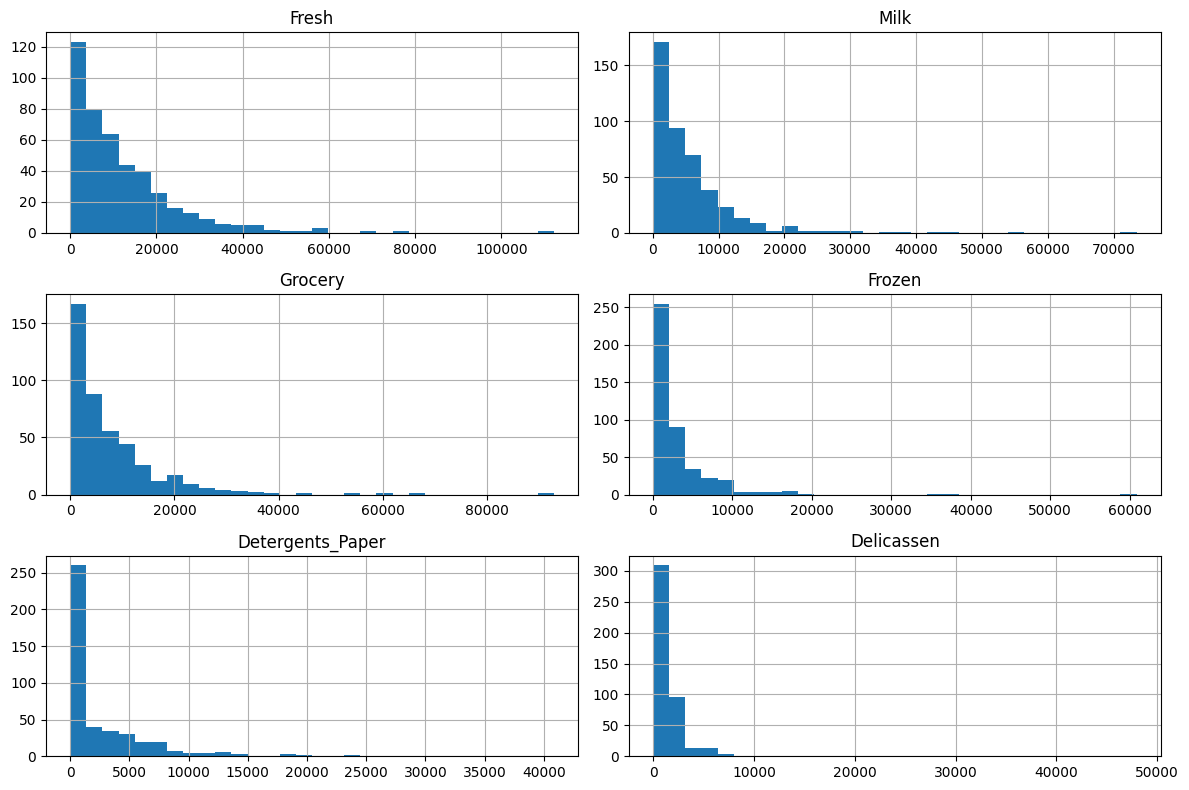

In [6]:
import matplotlib.pyplot as plt

df[spending_columns].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

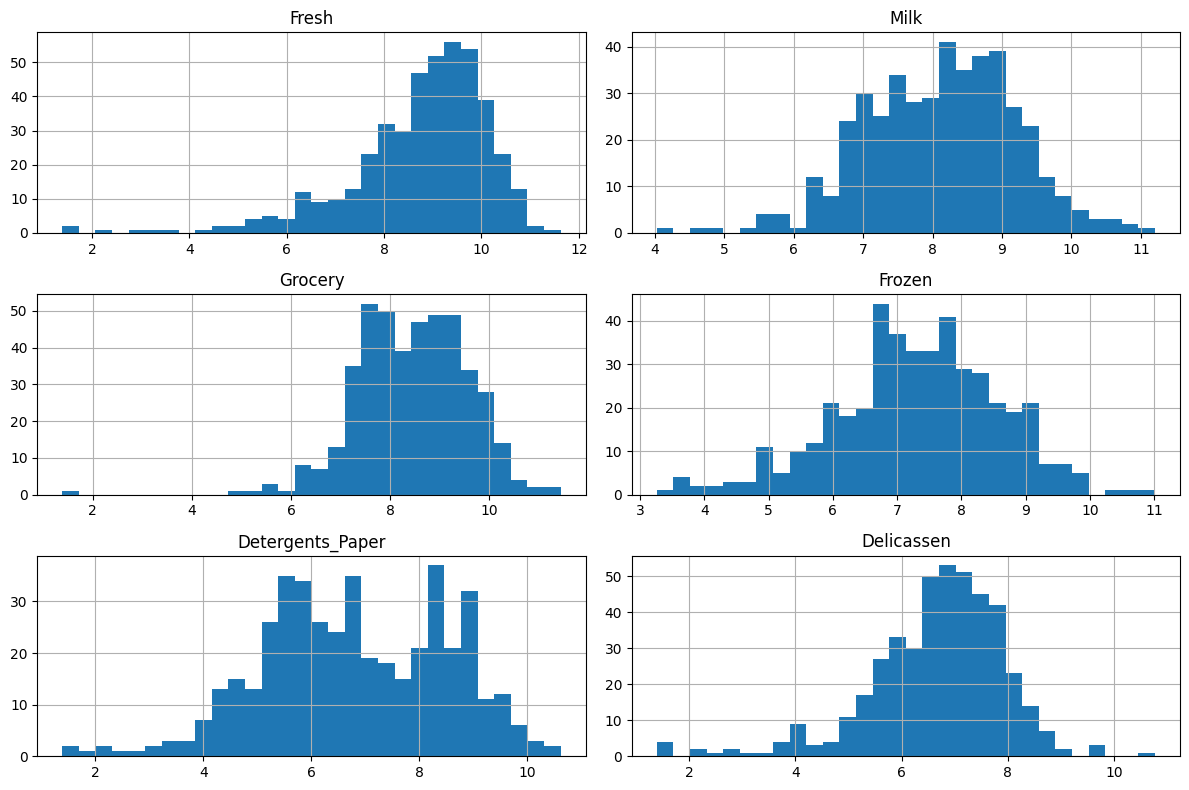

In [7]:
import numpy as np
spending_log = np.log1p(df[spending_columns])

spending_log.hist(figsize = (12,8), bins = 30)
plt.tight_layout()
plt.show()

In [8]:
print("Original skewness:")
print(df[spending_columns].skew().round(2))

print("\nSkewness after log transformation:")
print(spending_log.skew().round(2))

Original skewness:
Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15
dtype: float64

Skewness after log transformation:
Fresh              -1.58
Milk               -0.22
Grocery            -0.67
Frozen             -0.35
Detergents_Paper   -0.24
Delicassen         -1.09
dtype: float64


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
spending_scaled = scaler.fit_transform(spending_log)

print("Shape:", spending_scaled.shape)
print("Means:", spending_scaled.mean(axis=0).round(2))
print("Standard deviations:", spending_scaled.std(axis=0).round(2))

Shape: (440, 6)
Means: [ 0. -0. -0.  0. -0. -0.]
Standard deviations: [1. 1. 1. 1. 1. 1.]


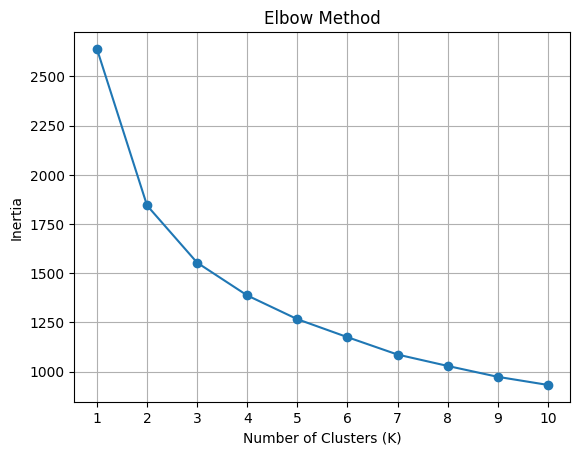

In [10]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(spending_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [11]:
from sklearn.metrics import silhouette_score

for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(spending_scaled)
    score = silhouette_score(spending_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.290
K = 3, Silhouette Score = 0.259
K = 4, Silhouette Score = 0.188
K = 5, Silhouette Score = 0.192
K = 6, Silhouette Score = 0.201
K = 7, Silhouette Score = 0.196


In [12]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = final_kmeans.fit_predict(spending_scaled)

df["Cluster"] = labels

print(df["Cluster"].value_counts().sort_index())

Cluster
0    252
1    188
Name: count, dtype: int64


In [13]:
cluster_profiles = df.groupby("Cluster")[spending_columns].mean()

print(cluster_profiles.round(2))

            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0        13973.13   2401.75   2918.71  3705.67            491.94     1038.04
1         9355.87  10346.36  14697.06  2222.45           6084.51     2177.43


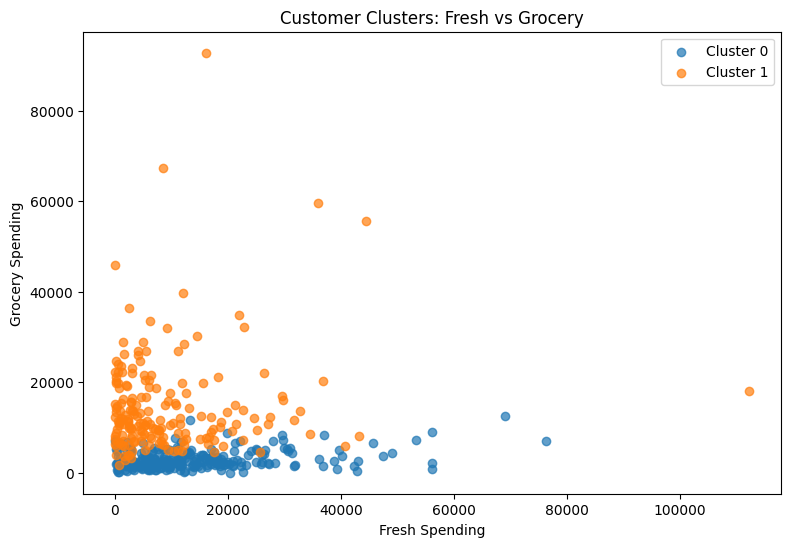

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    subset = df[df["Cluster"] == cluster]
    plt.scatter(
        subset["Fresh"],
        subset["Grocery"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Fresh Spending")
plt.ylabel("Grocery Spending")
plt.title("Customer Clusters: Fresh vs Grocery")
plt.legend()
plt.show()

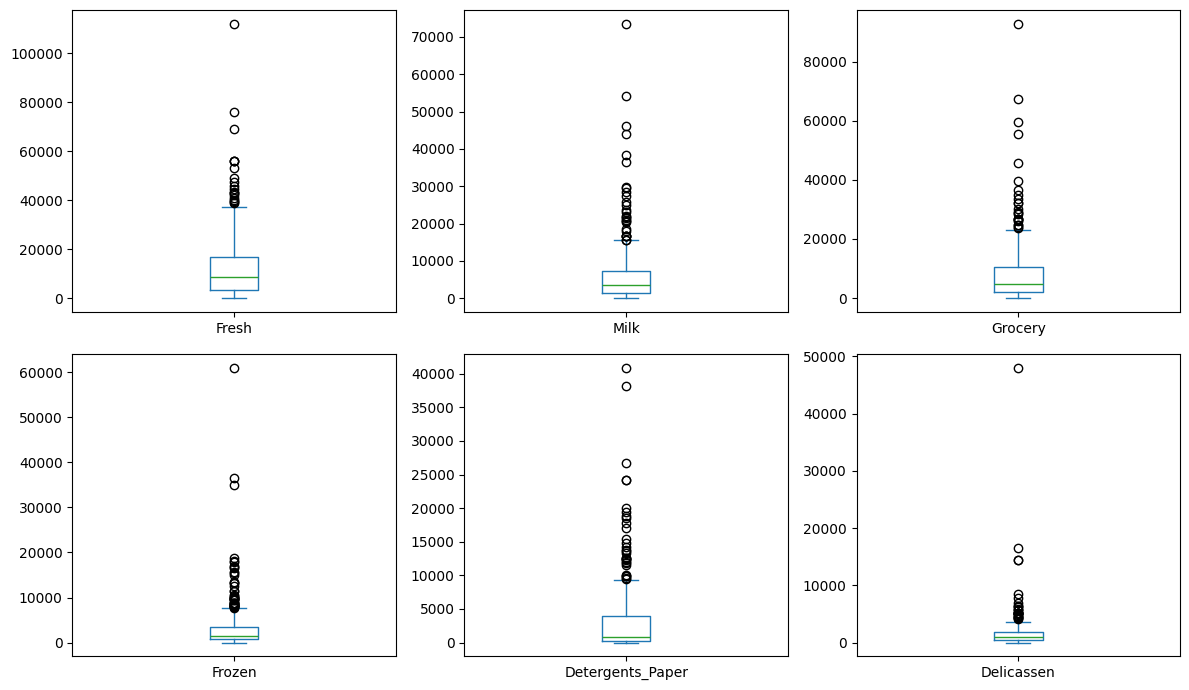

In [15]:
import matplotlib.pyplot as plt

df[spending_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(12, 7),
    sharey=False
)

plt.tight_layout()
plt.show()

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Original spending values, scaled
original_scaled = StandardScaler().fit_transform(
    df[spending_columns]
)

original_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

original_labels = original_model.fit_predict(original_scaled)

print(
    "Original data silhouette:",
    round(silhouette_score(original_scaled, original_labels), 3)
)

print(
    "Log-transformed data silhouette:",
    round(silhouette_score(spending_scaled, labels), 3)
)

Original data silhouette: 0.547
Log-transformed data silhouette: 0.29


In [17]:
print(
    pd.Series(original_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

Cluster
0    389
1     51
Name: count, dtype: int64


In [18]:
original_profiles = (
    df[spending_columns]
    .groupby(original_labels)
    .mean()
)

print(original_profiles.round(2))

      Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
0  12157.30   4028.17   5402.72  3066.07           1667.69     1256.89
1  10802.76  19282.33  27390.25  3116.67          12139.73     3568.84


In [19]:
for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_k = model.fit_predict(original_scaled)
    score = silhouette_score(original_scaled, labels_k)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.547
K = 3, Silhouette Score = 0.548
K = 4, Silhouette Score = 0.348
K = 5, Silhouette Score = 0.369
K = 6, Silhouette Score = 0.378
K = 7, Silhouette Score = 0.334


In [20]:
from sklearn.cluster import KMeans
import pandas as pd

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(original_scaled)

    print(f"\nK = {k}")
    print(pd.Series(cluster_labels).value_counts().sort_index())

    profiles = df[spending_columns].groupby(cluster_labels).mean()
    print(profiles.round(0))


K = 2
0    389
1     51
Name: count, dtype: int64
     Fresh     Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12157.0   4028.0   5403.0  3066.0            1668.0      1257.0
1  10803.0  19282.0  27390.0  3117.0           12140.0      3569.0

K = 3
0     45
1    393
2      2
Name: count, dtype: int64
     Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
0  10441.0  19386.0  28656.0   2190.0           13328.0      2374.0
1  12063.0   4115.0   5535.0   2941.0            1696.0      1299.0
2  34782.0  30367.0  16898.0  48702.0             756.0     26776.0


In [21]:
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_3 = kmeans_3.fit_predict(original_scaled)

cluster_2_customers = df.loc[
    labels_3 == 2,
    spending_columns
]

print(cluster_2_customers)

     Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
183  36847  43950    20170   36534               239       47943
325  32717  16784    13626   60869              1272        5609


In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for seed in [0, 21, 42, 100]:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )

    cluster_labels = model.fit_predict(original_scaled)

    counts = pd.Series(cluster_labels).value_counts().sort_index()

    print(
        f"Seed={seed}, "
        f"Cluster sizes={counts.tolist()}, "
        f"Silhouette={silhouette_score(original_scaled, cluster_labels):.3f}"
    )

Seed=0, Cluster sizes=[49, 391], Silhouette=0.567
Seed=21, Cluster sizes=[395, 45], Silhouette=0.563
Seed=42, Cluster sizes=[389, 51], Silhouette=0.547
Seed=100, Cluster sizes=[42, 398], Silhouette=0.591


In [23]:
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans

labels_by_seed = {}

for seed in [0, 21, 42, 100]:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )
    labels_by_seed[seed] = model.fit_predict(original_scaled)

reference = labels_by_seed[42]

for seed, labels in labels_by_seed.items():
    score = adjusted_rand_score(reference, labels)
    print(f"Seed {seed} vs Seed 42: ARI = {score:.3f}")

Seed 0 vs Seed 42: ARI = 0.944
Seed 21 vs Seed 42: ARI = 0.914
Seed 42 vs Seed 42: ARI = 1.000
Seed 100 vs Seed 42: ARI = 0.841


In [24]:
df["Original_Cluster"] = original_labels

cluster_profile = (
    df.groupby("Original_Cluster")[spending_columns]
      .mean()
      .round(2)
)

print(cluster_profile)

                     Fresh      Milk   Grocery   Frozen  Detergents_Paper  \
Original_Cluster                                                            
0                 12157.30   4028.17   5402.72  3066.07           1667.69   
1                 10802.76  19282.33  27390.25  3116.67          12139.73   

                  Delicassen  
Original_Cluster              
0                    1256.89  
1                    3568.84  


In [25]:
pd.crosstab(
    df["Original_Cluster"],
    df["Channel"],
    normalize="index"
).round(3) * 100

Channel,1,2
Original_Cluster,,
0,75.3,24.7
1,9.8,90.2


In [26]:
pd.crosstab(
    df["Original_Cluster"],
    df["Region"],
    normalize="index"
).round(3) * 100

Region,1,2,3
Original_Cluster,,,
0,17.5,10.0,72.5
1,17.6,15.7,66.7
